In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_auc_score, log_loss
)

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("Dataset Shape:", df.shape)

df.info()

display(df.describe)

Dataset Shape: (7043, 21)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-

<bound method NDFrame.describe of       customerID  gender  SeniorCitizen Partner Dependents  tenure  \
0     7590-VHVEG  Female              0     Yes         No       1   
1     5575-GNVDE    Male              0      No         No      34   
2     3668-QPYBK    Male              0      No         No       2   
3     7795-CFOCW    Male              0      No         No      45   
4     9237-HQITU  Female              0      No         No       2   
...          ...     ...            ...     ...        ...     ...   
7038  6840-RESVB    Male              0     Yes        Yes      24   
7039  2234-XADUH  Female              0     Yes        Yes      72   
7040  4801-JZAZL  Female              0     Yes        Yes      11   
7041  8361-LTMKD    Male              1     Yes         No       4   
7042  3186-AJIEK    Male              0      No         No      66   

     PhoneService     MultipleLines InternetService OnlineSecurity  ...  \
0              No  No phone service             DS

In [5]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nUnique Values:")
print(df.nunique())

Missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate Rows: 0

Unique Values:
customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585

In [6]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

df["TotalCharges"] = df["TotalCharges"].fillna(
    df["TotalCharges"].median()
)

print("Missing Values After Cleaning:")
print(df.isnull().sum().sum())

print("Dataset Shape:", df.shape)

Missing Values After Cleaning:
0
Dataset Shape: (7043, 21)


In [8]:
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

categorical_columns = df.select_dtypes(include=['object', 'str']).columns

print("Numerical Columns:")
print(list(numerical_columns))

print("\nCategorical Columns:")
print(list(categorical_columns))

Numerical Columns:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Columns:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


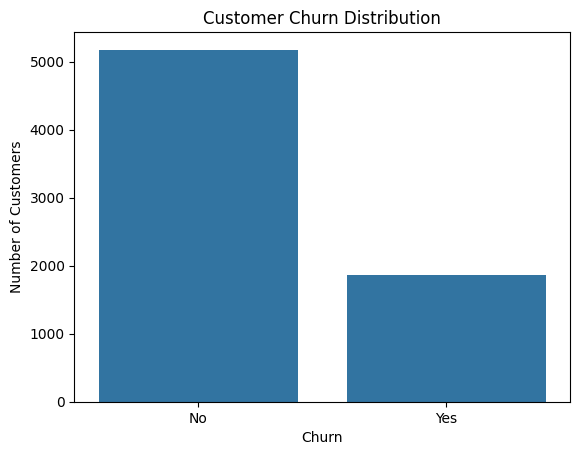

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [9]:
sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

print(df["Churn"].value_counts())

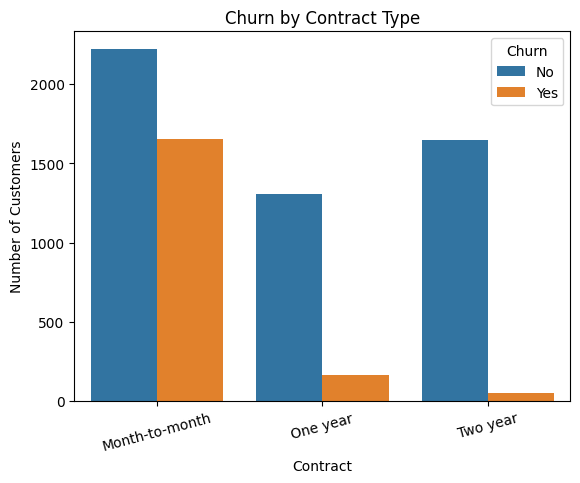

In [10]:
sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Churn by Contract Type")
plt.xlabel("Contract")
plt.ylabel("Number of Customers")

plt.xticks(rotation=15)

plt.show()

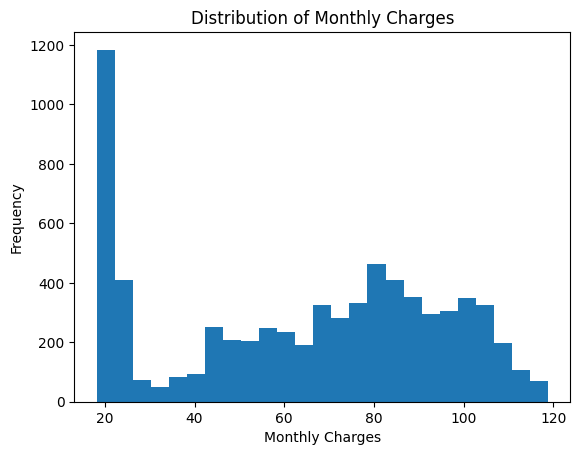

In [11]:
plt.hist(df["MonthlyCharges"], bins=25)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Frequency")

plt.show()

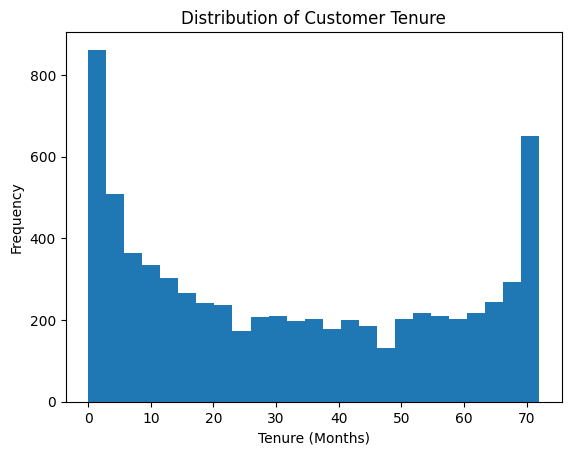

In [12]:
plt.hist(df["tenure"], bins=25)

plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Frequency")

plt.show()

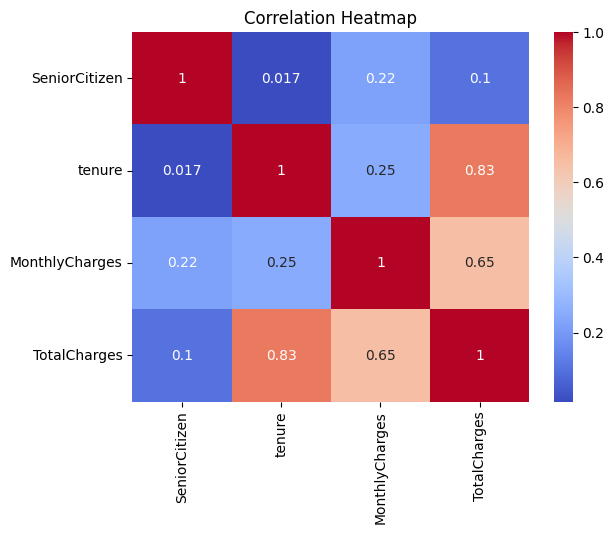

In [13]:
correlation = df[
    ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
].corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap")

plt.show()

In [14]:
X_reg = df[["tenure", "MonthlyCharges"]]
y_reg = df["TotalCharges"]

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

print("Training Records:", X_reg_train.shape[0])
print("Testing Records:", X_reg_test.shape[0])

Training Records: 5634
Testing Records: 1409


In [15]:
X_simple = df[["tenure"]]
y_simple = df["TotalCharges"]

X_simple_train, X_simple_test, y_simple_train, y_simple_test = train_test_split(
    X_simple, y_simple, test_size=0.2, random_state=42
)

simple_model = LinearRegression()

simple_model.fit(X_simple_train, y_simple_train)

simple_predictions = simple_model.predict(X_simple_test)

print("MAE:", mean_absolute_error(y_simple_test, simple_predictions))
print("MSE:", mean_squared_error(y_simple_test, simple_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_simple_test, simple_predictions)))
print("R-squared:", r2_score(y_simple_test, simple_predictions))

MAE: 892.0415772496405
MSE: 1717993.9247736859
RMSE: 1310.7226727167292
R-squared: 0.6695741445638115


In [16]:
multiple_model = LinearRegression()

multiple_model.fit(X_reg_train, y_reg_train)

multiple_predictions = multiple_model.predict(X_reg_test)

print("MAE:", mean_absolute_error(y_reg_test, multiple_predictions))
print("MSE:", mean_squared_error(y_reg_test, multiple_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_reg_test, multiple_predictions)))
print("R-squared:", r2_score(y_reg_test, multiple_predictions))

MAE: 604.3669462195941
MSE: 571599.1336500349
RMSE: 756.041753906512
R-squared: 0.8900629798631114


In [17]:
X_poly = df[["tenure"]]
y_poly = df["TotalCharges"]

X_poly_train, X_poly_test, y_poly_train, y_poly_test = train_test_split(
    X_poly, y_poly, test_size=0.2, random_state=42
)

poly_features = PolynomialFeatures(degree=2)

X_poly_train_transformed = poly_features.fit_transform(X_poly_train)
X_poly_test_transformed = poly_features.transform(X_poly_test)

poly_model = LinearRegression()

poly_model.fit(X_poly_train_transformed, y_poly_train)

poly_predictions = poly_model.predict(X_poly_test_transformed)

print("MAE:", mean_absolute_error(y_poly_test, poly_predictions))
print("MSE:", mean_squared_error(y_poly_test, poly_predictions))
print("RMSE:", np.sqrt(mean_squared_error(y_poly_test, poly_predictions)))
print("R-squared:", r2_score(y_poly_test, poly_predictions))

MAE: 866.2083361429076
MSE: 1702028.0778993813
RMSE: 1304.6179815943751
R-squared: 0.6726448938459432


In [18]:
regression_results = pd.DataFrame({
    "Model": [
        "Simple Linear",
        "Multiple Linear",
        "Polynomial"
    ],
    "MAE": [
        mean_absolute_error(y_simple_test, simple_predictions),
        mean_absolute_error(y_reg_test, multiple_predictions),
        mean_absolute_error(y_poly_test, poly_predictions)
    ],
    "MSE": [
        mean_squared_error(y_simple_test, simple_predictions),
        mean_squared_error(y_reg_test, multiple_predictions),
        mean_squared_error(y_poly_test, poly_predictions)
    ],
    "R2 Score": [
        r2_score(y_simple_test, simple_predictions),
        r2_score(y_reg_test, multiple_predictions),
        r2_score(y_poly_test, poly_predictions)
    ]
})

display(regression_results)

,Model,MAE,MSE,R2 Score
0,Simple Linear,892.041577,1.717994e+06,0.669574
1,Multiple Linear,604.366946,5.715991e+05,0.890063
2,Polynomial,866.208336,1.702028e+06,0.672645


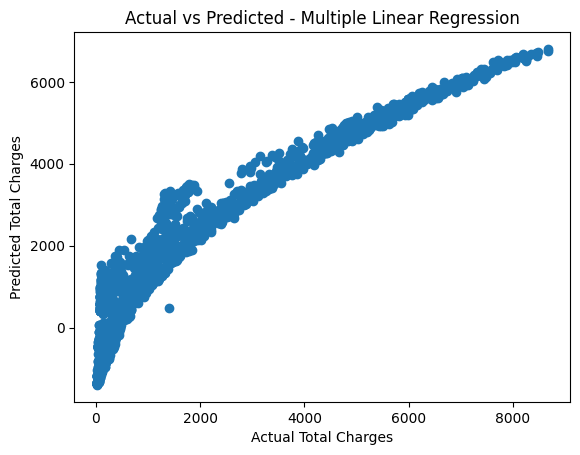

In [19]:
plt.scatter(y_reg_test, multiple_predictions)

plt.xlabel("Actual Total Charges")
plt.ylabel("Predicted Total Charges")

plt.title("Actual vs Predicted - Multiple Linear Regression")

plt.show()

In [20]:
X = df.drop(["customerID", "Churn"], axis=1)

y = df["Churn"].map({"No": 0, "Yes": 1})

X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

print("Number of Features:", X_train.shape[1])

Training Records: 5634
Testing Records: 1409
Number of Features: 30


In [21]:
logistic_model = LogisticRegression(max_iter=1000)

logistic_model.fit(X_train_scaled, y_train)

logistic_predictions = logistic_model.predict(X_test_scaled)

logistic_probabilities = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", accuracy_score(y_test, logistic_predictions))
print("Precision:", precision_score(y_test, logistic_predictions, zero_division=0))
print("Recall:", recall_score(y_test, logistic_predictions, zero_division=0))
print("F1 Score:", f1_score(y_test, logistic_predictions, zero_division=0))
print("AUC:", roc_auc_score(y_test, logistic_probabilities))
print("Log Loss:", log_loss(y_test, logistic_model.predict_proba(X_test_scaled)))

Accuracy: 0.8069552874378992
Precision: 0.6583850931677019
Recall: 0.5668449197860963
F1 Score: 0.6091954022988506
AUC: 0.8415846443979436
Log Loss: 0.4209262720211592


In [22]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

knn_predictions = knn_model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, knn_predictions))
print("Precision:", precision_score(y_test, knn_predictions, zero_division=0))
print("Recall:", recall_score(y_test, knn_predictions, zero_division=0))
print("F1 Score:", f1_score(y_test, knn_predictions, zero_division=0))

Accuracy: 0.7473385379701917
Precision: 0.5252808988764045
Recall: 0.5
F1 Score: 0.5123287671232877


In [23]:
nb_model = GaussianNB()

nb_model.fit(X_train_scaled, y_train)

nb_predictions = nb_model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, nb_predictions))
print("Precision:", precision_score(y_test, nb_predictions, zero_division=0))
print("Recall:", recall_score(y_test, nb_predictions, zero_division=0))
print("F1 Score:", f1_score(y_test, nb_predictions, zero_division=0))

Accuracy: 0.6557842441447835
Precision: 0.4268774703557312
Recall: 0.8663101604278075
F1 Score: 0.5719329214474845


In [24]:
tree_model = DecisionTreeClassifier(random_state=42)

tree_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, tree_predictions))
print("Precision:", precision_score(y_test, tree_predictions, zero_division=0))
print("Recall:", recall_score(y_test, tree_predictions, zero_division=0))
print("F1 Score:", f1_score(y_test, tree_predictions, zero_division=0))

Accuracy: 0.7416607523066004
Precision: 0.5138888888888888
Recall: 0.4946524064171123
F1 Score: 0.5040871934604905


In [25]:
svm_model = SVC(
    kernel="linear",
    probability=True,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

svm_predictions = svm_model.predict(X_test_scaled)

svm_probabilities = svm_model.predict_proba(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, svm_predictions))
print("Precision:", precision_score(y_test, svm_predictions, zero_division=0))
print("Recall:", recall_score(y_test, svm_predictions, zero_division=0))
print("F1 Score:", f1_score(y_test, svm_predictions, zero_division=0))
print("AUC:", roc_auc_score(y_test, svm_probabilities[:, 1]))
print("Log Loss:", log_loss(y_test, svm_probabilities))

Accuracy: 0.7892122072391767
Precision: 0.6206896551724138
Recall: 0.5294117647058824
F1 Score: 0.5714285714285714
AUC: 0.8244800950683304
Log Loss: 0.4423567535749598


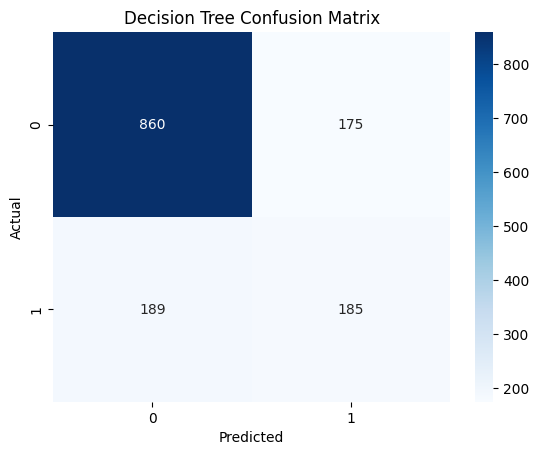

In [26]:
cm = confusion_matrix(y_test, tree_predictions)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.title("Decision Tree Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [27]:
cluster_data = df[
    ["tenure", "MonthlyCharges", "TotalCharges"]
]

cluster_scaler = StandardScaler()

cluster_scaled = cluster_scaler.fit_transform(cluster_data)

print("Data Prepared for Clustering:", cluster_scaled.shape)

Data Prepared for Clustering: (7043, 3)


In [28]:
kmeans_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df["KMeansCluster"] = kmeans_model.fit_predict(cluster_scaled)

print(df["KMeansCluster"].value_counts())

display(
    df.groupby("KMeansCluster")[
        ["tenure", "MonthlyCharges", "TotalCharges"]
    ].mean()
)

KMeansCluster
2    2689
1    2200
0    2154
Name: count, dtype: int64


,tenure,MonthlyCharges,TotalCharges
KMeansCluster,,,
0,29.498143,26.572864,813.312604
1,58.559545,89.697932,5246.126386
2,13.246560,74.950985,1033.167544


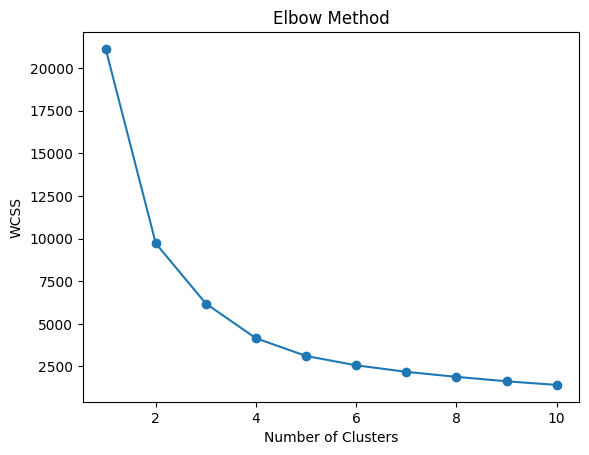

In [29]:
wcss = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(cluster_scaled)

    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker="o")

plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")

plt.show()

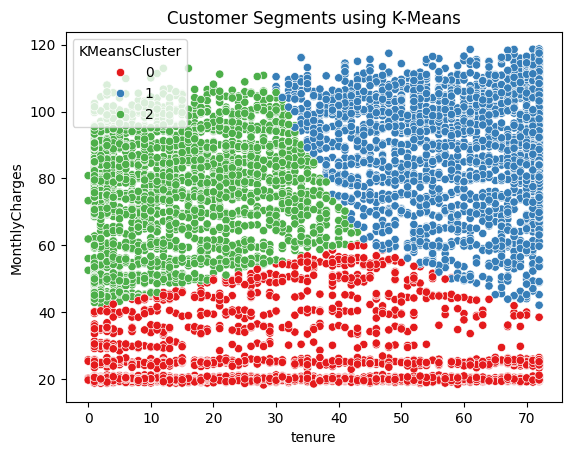

In [30]:
sns.scatterplot(
    data=df,
    x="tenure",
    y="MonthlyCharges",
    hue="KMeansCluster",
    palette="Set1"
)

plt.title("Customer Segments using K-Means")

plt.show()

In [31]:
hierarchical_data = cluster_scaled[:500]

hierarchical_model = AgglomerativeClustering(
    n_clusters=3,
    linkage="average"
)

hierarchical_labels = hierarchical_model.fit_predict(
    hierarchical_data
)

print("Hierarchical Cluster Counts:")

print(
    pd.Series(hierarchical_labels).value_counts().sort_index()
)

Hierarchical Cluster Counts:
0    160
1    115
2    225
Name: count, dtype: int64


In [32]:
hierarchical_result = df.iloc[:500][
    ["tenure", "MonthlyCharges", "TotalCharges"]
].copy()

hierarchical_result["HierarchicalCluster"] = hierarchical_labels

display(
    hierarchical_result.groupby("HierarchicalCluster")[
        ["tenure", "MonthlyCharges", "TotalCharges"]
    ].mean()
)

,tenure,MonthlyCharges,TotalCharges
HierarchicalCluster,,,
0,22.506250,30.206250,554.419219
1,63.643478,87.201739,5531.419130
2,21.364444,80.558889,1715.826000


In [33]:
pca_model = PCA(n_components=2)

X_train_pca = pca_model.fit_transform(X_train_scaled)

X_test_pca = pca_model.transform(X_test_scaled)

print("Explained Variance Ratio:")

print(pca_model.explained_variance_ratio_)

print(
    "Total Explained Variance:",
    pca_model.explained_variance_ratio_.sum()
)

Explained Variance Ratio:
[0.33246151 0.11980321]
Total Explained Variance: 0.45226472427671316


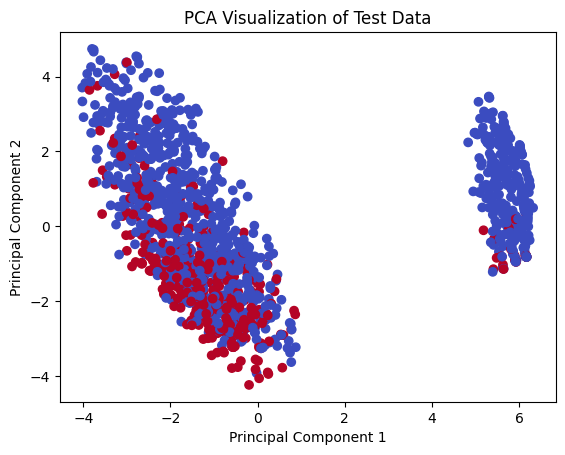

In [34]:
plt.scatter(
    X_test_pca[:, 0],
    X_test_pca[:, 1],
    c=y_test,
    cmap="coolwarm"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("PCA Visualization of Test Data")

plt.show()

In [36]:
mlp_model = MLPClassifier(hidden_layer_sizes=(50, 25), max_iter=1000, random_state=42)

mlp_model.fit(X_train_scaled, y_train)

mlp_predictions = mlp_model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, mlp_predictions))
print("Precision:", precision_score(y_test, mlp_predictions, zero_division=0))
print("Recall:", recall_score(y_test, mlp_predictions, zero_division=0))
print("F1 Score:", f1_score(y_test, mlp_predictions, zero_division=0))

Accuracy: 0.751596877217885
Precision: 0.5338983050847458
Recall: 0.5053475935828877
F1 Score: 0.5192307692307693


In [37]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_probabilities = rf_model.predict_proba(X_test)

print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("Precision:", precision_score(y_test, rf_predictions, zero_division=0))
print("Recall:", recall_score(y_test, rf_predictions, zero_division=0))
print("F1 Score:", f1_score(y_test, rf_predictions, zero_division=0))
print("AUC:", roc_auc_score(y_test, rf_probabilities[:, 1]))
print("Log Loss:", log_loss(y_test, rf_probabilities))

Accuracy: 0.7863733144073811
Precision: 0.6237288135593221
Recall: 0.4919786096256685
F1 Score: 0.5500747384155455
AUC: 0.8250807305794517
Log Loss: 0.48663429603661756


In [38]:
classification_results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "KNN",
        "Naive Bayes",
        "Decision Tree",
        "SVM",
        "MLP",
        "Random Forest"
    ],

    "Accuracy": [
        accuracy_score(y_test, logistic_predictions),
        accuracy_score(y_test, knn_predictions),
        accuracy_score(y_test, nb_predictions),
        accuracy_score(y_test, tree_predictions),
        accuracy_score(y_test, svm_predictions),
        accuracy_score(y_test, mlp_predictions),
        accuracy_score(y_test, rf_predictions)
    ],

    "Precision": [
        precision_score(y_test, logistic_predictions, zero_division=0),
        precision_score(y_test, knn_predictions, zero_division=0),
        precision_score(y_test, nb_predictions, zero_division=0),
        precision_score(y_test, tree_predictions, zero_division=0),
        precision_score(y_test, svm_predictions, zero_division=0),
        precision_score(y_test, mlp_predictions, zero_division=0),
        precision_score(y_test, rf_predictions, zero_division=0)
    ],

    "Recall": [
        recall_score(y_test, logistic_predictions, zero_division=0),
        recall_score(y_test, knn_predictions, zero_division=0),
        recall_score(y_test, nb_predictions, zero_division=0),
        recall_score(y_test, tree_predictions, zero_division=0),
        recall_score(y_test, svm_predictions, zero_division=0),
        recall_score(y_test, mlp_predictions, zero_division=0),
        recall_score(y_test, rf_predictions, zero_division=0)
    ],

    "F1 Score": [
        f1_score(y_test, logistic_predictions, zero_division=0),
        f1_score(y_test, knn_predictions, zero_division=0),
        f1_score(y_test, nb_predictions, zero_division=0),
        f1_score(y_test, tree_predictions, zero_division=0),
        f1_score(y_test, svm_predictions, zero_division=0),
        f1_score(y_test, mlp_predictions, zero_division=0),
        f1_score(y_test, rf_predictions, zero_division=0)
    ]

})

display(
    classification_results.sort_values(
        by="Accuracy",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.806955,0.658385,0.566845,0.609195
4,SVM,0.789212,0.620690,0.529412,0.571429
6,Random Forest,0.786373,0.623729,0.491979,0.550075
5,MLP,0.751597,0.533898,0.505348,0.519231
1,KNN,0.747339,0.525281,0.500000,0.512329
3,Decision Tree,0.741661,0.513889,0.494652,0.504087
2,Naive Bayes,0.655784,0.426877,0.866310,0.571933


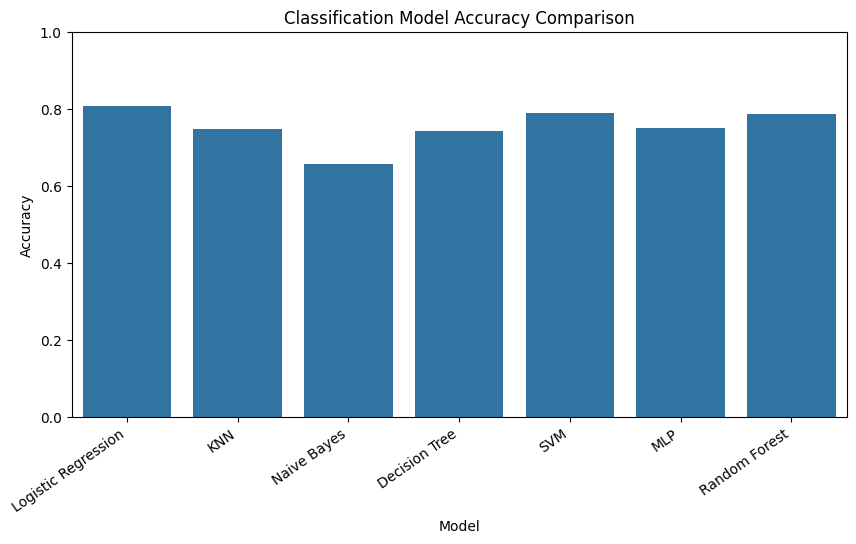

In [39]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=classification_results,
    x="Model",
    y="Accuracy"
)

plt.title("Classification Model Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Accuracy")

plt.xticks(rotation=35, ha="right")

plt.ylim(0, 1)

plt.show()

In [40]:
print("PROJECT: TELECOM CUSTOMER CHURN PREDICTION AND ANALYSIS")

print("Original Dataset Records:", len(df))

print("Number of Classification Features:", X.shape[1])

print("\nRegression Models:")
print("1. Simple Linear Regression")
print("2. Multiple Linear Regression")
print("3. Polynomial Regression")

print("\nClassification Models:")
print("1. Logistic Regression")
print("2. KNN")
print("3. Naive Bayes")
print("4. Decision Tree")
print("5. SVM")

print("\nClustering Methods:")
print("1. K-Means")
print("2. Hierarchical Agglomerative Clustering")

print("\nDimensionality Reduction:")
print("PCA")

print("\nNeural Network:")
print("Multi-layer Perceptron")

print("\nEnsemble Model:")
print("Random Forest")

print("\nBest Classification Model by Accuracy:")

print(
    classification_results.sort_values(
        by="Accuracy",
        ascending=False
    ).iloc[0][["Model", "Accuracy"]]
)

PROJECT: TELECOM CUSTOMER CHURN PREDICTION AND ANALYSIS
Original Dataset Records: 7043
Number of Classification Features: 30

Regression Models:
1. Simple Linear Regression
2. Multiple Linear Regression
3. Polynomial Regression

Classification Models:
1. Logistic Regression
2. KNN
3. Naive Bayes
4. Decision Tree
5. SVM

Clustering Methods:
1. K-Means
2. Hierarchical Agglomerative Clustering

Dimensionality Reduction:
PCA

Neural Network:
Multi-layer Perceptron

Ensemble Model:
Random Forest

Best Classification Model by Accuracy:
Model       Logistic Regression
Accuracy               0.806955
Name: 0, dtype: object
